# Lab 2 - What Did the Campaign Deliver?
Name: Oleksandr Serpovych Liubomyrovych | Group: KM-41

## Setup

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

## Task 1.1 - Size

In [2]:
num_spots = len(commercials)
num_pods = commercials['pod_id'].nunique()
num_brands = commercials['brand'].nunique()
num_categories = commercials['category'].nunique()

brand_a_spots_df = commercials[commercials['brand'] == 'BRAND_A'].copy()
num_brand_a_spots = len(brand_a_spots_df)

print("Spots:", num_spots)
print("Pods:", num_pods)
print("Brands:", num_brands)
print("Categories:", num_categories)
print("BRAND_A spots:", num_brand_a_spots)

# table: BRAND_A spots by network
brand_a_by_net = (
    brand_a_spots_df.groupby('network_code')['ad_airing_id']
    .count()
    .reset_index(name='brand_a_spots')
    .sort_values('brand_a_spots', ascending=False)
    .reset_index(drop=True)
)
display(brand_a_by_net)

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,network_code,brand_a_spots
0,FNC,40
1,HGTV,39
2,FX,38
3,HIST,37
4,FOOD,33
5,BRAVO,33
6,ABC,29
7,CBS,22
8,NBC,16
9,FOX,13


## Task 1.2 - Ad load

In [3]:
comm_hours = commercials.copy()
comm_hours['clock_hour_bucket'] = comm_hours['start_ts'].dt.floor('h')

hourly_ad_load = (
    comm_hours.groupby(['network_code', 'clock_hour_bucket'])['length_sec']
    .sum()
    .reset_index()
)
hourly_ad_load['ad_minutes'] = hourly_ad_load['length_sec'] / 60.0

ad_load_by_net = (
    hourly_ad_load.groupby('network_code')
    .agg(
        hours_with_ads=('clock_hour_bucket', 'count'),
        ad_minutes_per_hour=('ad_minutes', 'mean')
    )
    .reset_index()
    .sort_values('ad_minutes_per_hour', ascending=False)
    .reset_index(drop=True)
)
ad_load_by_net['ad_minutes_per_hour'] = ad_load_by_net['ad_minutes_per_hour'].round(1)

# table: ad minutes per hour by network
display(ad_load_by_net)

heaviest_net = ad_load_by_net.iloc[0]['network_code']
print("Heaviest ad load:", heaviest_net)

,network_code,hours_with_ads,ad_minutes_per_hour
0,FNC,743,15.6
1,BRAVO,623,13.4
2,HGTV,621,13.3
3,HIST,622,13.2
4,FOOD,620,13.1
5,FX,621,12.9
6,CBS,427,12.1
7,ABC,349,11.8
8,NBC,299,11.8
9,FOX,196,11.8


Heaviest ad load: FNC


**Answer:** Broadcast networks have hours without national ads because they allocate specific "local-station hours" to their local affiliates, allowing them to sell advertising inventory in their own local markets. Since these spots are sold locally rather than nationally, they do not appear in the national commercial log.

## Task 1.3 - Price everything

In [4]:
spots_priced = commercials.merge(
    programs[['telecast_id', 'program_name', 'broadcast_date']],
    on='telecast_id',
    how='left'
)

# Separate program rows and time rows in rate_card
is_prog_rc = rate_card['program_name'].notna() & (rate_card['program_name'].astype(str).str.strip() != '')
prog_rc = rate_card[is_prog_rc][['network_code', 'program_name', 'daypart', 'cost_30s_usd']].copy()
time_rc = rate_card[~is_prog_rc].copy()

# Match program rows first (program row wins)
spots_priced = spots_priced.merge(
    prog_rc.rename(columns={'daypart': 'prog_daypart', 'cost_30s_usd': 'prog_cost_30s'}),
    on=['network_code', 'program_name'],
    how='left'
)

# Match remaining spots using broadcast weekday and minutes since 06:00
unmatched_mask = spots_priced['prog_cost_30s'].isna()
unmatched_spots = spots_priced[unmatched_mask].copy()

ts_shifted = unmatched_spots['start_ts'] - pd.Timedelta(hours=6)
unmatched_spots['b_weekday'] = ts_shifted.dt.dayofweek
unmatched_spots['spot_min'] = ts_shifted.dt.hour * 60 + ts_shifted.dt.minute + ts_shifted.dt.second / 60.0

def parse_bcast_min(t_str):
    h, m = map(int, str(t_str).strip().split(':'))
    return h * 60 + m - 360

time_rc['start_min'] = time_rc['start_time'].apply(parse_bcast_min)
time_rc['end_min'] = time_rc['end_time'].apply(parse_bcast_min)

time_rc_exploded = time_rc.explode('weekdays').copy()
time_rc_exploded['b_weekday'] = time_rc_exploded['weekdays'].astype(int)

matched_time = unmatched_spots[['ad_airing_id', 'network_code', 'b_weekday', 'spot_min']].merge(
    time_rc_exploded[['network_code', 'b_weekday', 'start_min', 'end_min', 'daypart', 'cost_30s_usd']],
    on=['network_code', 'b_weekday'],
    how='left'
)
matched_time = matched_time[
    (matched_time['spot_min'] >= matched_time['start_min']) &
    (matched_time['spot_min'] < matched_time['end_min'])
]

spots_priced = spots_priced.merge(
    matched_time[['ad_airing_id', 'daypart', 'cost_30s_usd']].rename(
        columns={'daypart': 'time_daypart', 'cost_30s_usd': 'time_cost_30s'}
    ),
    on='ad_airing_id',
    how='left'
)

spots_priced['is_program_row'] = spots_priced['prog_cost_30s'].notna()
spots_priced['selling_daypart'] = spots_priced['prog_daypart'].fillna(spots_priced['time_daypart'])
spots_priced['cost_30s_usd'] = spots_priced['prog_cost_30s'].fillna(spots_priced['time_cost_30s'])
spots_priced['length_factor'] = spots_priced['length_sec'] / 30.0
spots_priced['cost_usd'] = spots_priced['cost_30s_usd'] * spots_priced['length_factor']

spots_without_price = int(spots_priced['cost_usd'].isna().sum())
print("Spots without a price:", spots_without_price)

# table: rate-card value by network (USD M) and share from program rows
spots_priced['prog_row_cost_usd'] = np.where(spots_priced['is_program_row'], spots_priced['cost_usd'], 0.0)

rc_val_by_net = (
    spots_priced.groupby('network_code')
    .agg(
        total_value_usd=('cost_usd', 'sum'),
        prog_value_usd=('prog_row_cost_usd', 'sum')
    )
    .reset_index()
)
rc_val_by_net['rate_card_value_usd_m'] = (rc_val_by_net['total_value_usd'] / 1e6).round(2)
rc_val_by_net['program_row_share'] = (rc_val_by_net['prog_value_usd'] / rc_val_by_net['total_value_usd']).round(3)
rc_val_by_net = rc_val_by_net[['network_code', 'rate_card_value_usd_m', 'program_row_share']].sort_values(
    'rate_card_value_usd_m', ascending=False
).reset_index(drop=True)

display(rc_val_by_net)

Spots without a price: 0


,network_code,rate_card_value_usd_m,program_row_share
0,CBS,818.78,0.230
1,NBC,724.32,0.342
2,ABC,708.79,0.432
3,FOX,696.17,0.835
4,FNC,315.85,0.000
5,HGTV,58.10,0.000
6,FX,42.51,0.000
7,FOOD,42.15,0.000
8,HIST,40.09,0.000
9,BRAVO,25.31,0.000


## Task 2.1 - Delivery

In [5]:
# Prepare persons universe (R and L only) and monthly weights
persons_dw = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()
persons_dw['b_date'] = pd.to_datetime(persons_dw['broadcast_date']).dt.date

monthly_weights = (
    persons_dw.groupby('respondent_id')['weight']
    .mean()
    .reset_index(name='monthly_weight')
)

# Identify A18-49 and W18-34 respondents from viewer_attributes & attributes
def extract_demographic_sets(va_df, attr_df):
    va = va_df.copy()
    attr = attr_df.copy()
    
    # Merge viewer_attributes with attributes to inspect labels/codes
    code_col = [c for c in attr.columns if c in va.columns][0]
    text_cols = [c for c in attr.columns if c != code_col]
    merged = va.merge(attr, on=code_col, how='left')
    merged['full_desc'] = merged[text_cols].astype(str).agg(' '.join, axis=1).str.lower()
    
    # Gender Female (code 202 or 'female' / 'women')
    female_mask = (merged[code_col] == 202) | merged['full_desc'].str.contains(r'\bfemale\b|\bwomen\b', regex=True)
    female_ids = set(merged.loc[female_mask, 'respondent_id'])
    
    # Extract age range bounds (e.g., 18-34, 35-49, 25-34, etc.)
    age_bounds = merged['full_desc'].str.extract(r'(\d+)\s*[-–]\s*(\d+)')
    merged['age_low'] = pd.to_numeric(age_bounds[0], errors='coerce')
    merged['age_high'] = pd.to_numeric(age_bounds[1], errors='coerce')
    
    a18_49_mask = (merged['age_low'] >= 18) & (merged['age_high'] <= 49)
    a18_34_mask = (merged['age_low'] >= 18) & (merged['age_high'] <= 34)
    
    a18_49_ids = set(merged.loc[a18_49_mask, 'respondent_id'])
    a18_34_ids = set(merged.loc[a18_34_mask, 'respondent_id'])
    w18_34_ids = female_ids.intersection(a18_34_ids)
    
    return a18_49_ids, w18_34_ids

a18_49_set, w18_34_set = extract_demographic_sets(viewer_attributes, attributes)

persons_dw['is_a18_49'] = persons_dw['respondent_id'].isin(a18_49_set)
persons_dw['is_w18_34'] = persons_dw['respondent_id'].isin(w18_34_set)
monthly_weights['is_a18_49'] = monthly_weights['respondent_id'].isin(a18_49_set)
monthly_weights['is_w18_34'] = monthly_weights['respondent_id'].isin(w18_34_set)

# Daily in-tab universe weights for P2+ and A18-49
daily_univ_p2 = persons_dw.groupby('b_date')['weight'].sum().to_dict()
daily_univ_a18_49 = persons_dw[persons_dw['is_a18_49']].groupby('b_date')['weight'].sum().to_dict()
daily_n_p2 = persons_dw.groupby('b_date')['respondent_id'].nunique().to_dict()

# Total monthly universe weights
total_monthly_p2 = monthly_weights['monthly_weight'].sum()
total_monthly_a18_49 = monthly_weights.loc[monthly_weights['is_a18_49'], 'monthly_weight'].sum()

# Build table of exposures for BRAND_A spots (session start <= spot start < session end)
brand_a_spots = spots_priced[spots_priced['brand'] == 'BRAND_A'].copy()
brand_a_spots['b_date'] = pd.to_datetime(brand_a_spots['broadcast_date']).dt.date

person_viewings = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

exposures = brand_a_spots[['ad_airing_id', 'telecast_id', 'network_code', 'start_ts', 'b_date', 'cost_usd', 'selling_daypart']].merge(
    person_viewings[['respondent_id', 'network_code', 'start_ts', 'end_ts', 'weight']].rename(
        columns={'start_ts': 'session_start', 'end_ts': 'session_end'}
    ),
    on='network_code',
    how='inner'
)
exposures = exposures[
    (exposures['session_start'] <= exposures['start_ts']) &
    (exposures['start_ts'] < exposures['session_end'])
].copy()

# Ensure one row per spot and person who saw it
exposures = exposures.drop_duplicates(subset=['ad_airing_id', 'respondent_id']).copy()
exposures['is_a18_49'] = exposures['respondent_id'].isin(a18_49_set)
exposures['is_w18_34'] = exposures['respondent_id'].isin(w18_34_set)

# Spot-level impressions and ratings
spot_imp_p2 = exposures.groupby('ad_airing_id')['weight'].sum()
spot_imp_a18_49 = exposures[exposures['is_a18_49']].groupby('ad_airing_id')['weight'].sum()

brand_a_spots['imp_p2'] = brand_a_spots['ad_airing_id'].map(spot_imp_p2).fillna(0.0)
brand_a_spots['imp_a18_49'] = brand_a_spots['ad_airing_id'].map(spot_imp_a18_49).fillna(0.0)

brand_a_spots['univ_p2'] = brand_a_spots['b_date'].map(daily_univ_p2)
brand_a_spots['univ_a18_49'] = brand_a_spots['b_date'].map(daily_univ_a18_49)

brand_a_spots['rating_p2'] = (brand_a_spots['imp_p2'] / brand_a_spots['univ_p2']) * 100.0
brand_a_spots['rating_a18_49'] = (brand_a_spots['imp_a18_49'] / brand_a_spots['univ_a18_49']) * 100.0

# Campaign totals for P2+
p2_impressions_m = brand_a_spots['imp_p2'].sum() / 1e6
p2_grps = brand_a_spots['rating_p2'].sum()
reached_p2_ids = set(exposures['respondent_id'])
p2_reach = (monthly_weights.loc[monthly_weights['respondent_id'].isin(reached_p2_ids), 'monthly_weight'].sum() / total_monthly_p2) * 100.0
p2_avg_freq = p2_grps / p2_reach

# Campaign totals for A18-49
a18_49_impressions_m = brand_a_spots['imp_a18_49'].sum() / 1e6
a18_49_grps = brand_a_spots['rating_a18_49'].sum()
reached_a18_49_ids = set(exposures.loc[exposures['is_a18_49'], 'respondent_id'])
a18_49_reach = (
    monthly_weights.loc[monthly_weights['is_a18_49'] & monthly_weights['respondent_id'].isin(reached_a18_49_ids), 'monthly_weight'].sum()
    / total_monthly_a18_49
) * 100.0
a18_49_avg_freq = a18_49_grps / a18_49_reach

print("P2+ impressions (M):", round(p2_impressions_m, 1))
print("P2+ GRPs:", round(p2_grps, 1))
print("P2+ reach (%):", round(p2_reach, 1))
print("P2+ average frequency:", round(p2_avg_freq, 1))
print("A18-49 impressions (M):", round(a18_49_impressions_m, 1))
print("A18-49 GRPs:", round(a18_49_grps, 1))
print("A18-49 reach (%):", round(a18_49_reach, 1))
print("A18-49 average frequency:", round(a18_49_avg_freq, 1))

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 - Frequency distribution

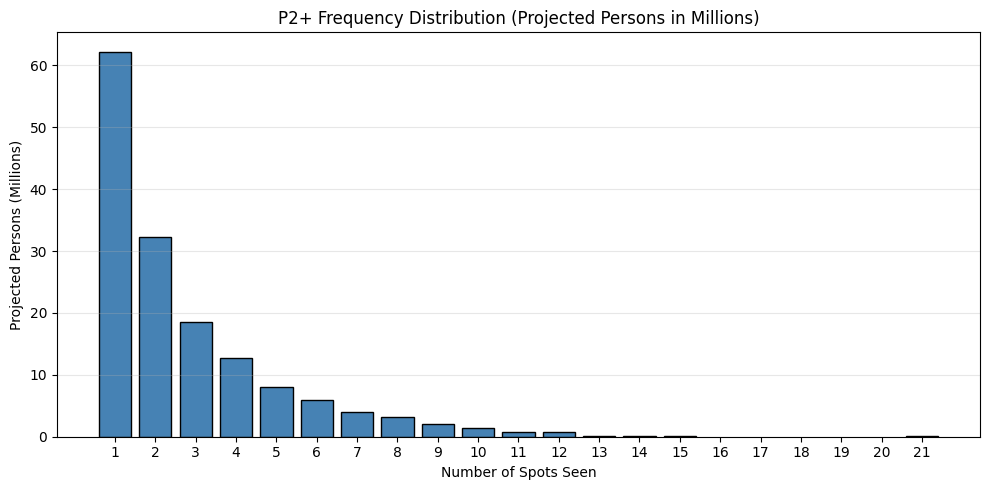

Share of impressions at 5+ exposures: 0.444


In [6]:
# Frequency per reached person
person_freq = (
    exposures.groupby('respondent_id')
    .agg(
        spots_seen=('ad_airing_id', 'count'),
        imp_sum=('weight', 'sum')
    )
    .reset_index()
    .merge(monthly_weights[['respondent_id', 'monthly_weight']], on='respondent_id', how='left')
)

freq_dist = (
    person_freq.groupby('spots_seen')['monthly_weight']
    .sum()
    .div(1e6)
    .reset_index(name='projected_persons_m')
)

# plot: projected persons (M) by number of spots seen
plt.figure(figsize=(10, 5))
plt.bar(freq_dist['spots_seen'], freq_dist['projected_persons_m'], color='steelblue', edgecolor='black')
plt.title('P2+ Frequency Distribution (Projected Persons in Millions)')
plt.xlabel('Number of Spots Seen')
plt.ylabel('Projected Persons (Millions)')
plt.xticks(range(1, int(freq_dist['spots_seen'].max()) + 1))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

share_imp_5plus = person_freq.loc[person_freq['spots_seen'] >= 5, 'imp_sum'].sum() / person_freq['imp_sum'].sum()
print("Share of impressions at 5+ exposures:", round(share_imp_5plus, 3))

**Answer:** No, the average frequency of 3.0 is not a fair summary of the campaign. The frequency distribution is highly right-skewed: the vast majority of reached viewers saw only 1 or 2 spots, while 44.4% of all impressions were delivered to a small, heavy-viewing segment that saw 5 or more spots, artificially pulling the average upward.

## Task 2.3 - On target?

In [7]:
share_on_a18_49 = brand_a_spots['imp_a18_49'].sum() / brand_a_spots['imp_p2'].sum()
print("Share of impressions on A18-49:", round(share_on_a18_49, 3))

Share of impressions on A18-49: 0.194


**Answer:** The campaign significantly under-delivered against its A18-49 target audience, capturing only a 19.4% share of impressions despite the target representing about 42% of the P2+ universe. This occurred because a large portion of the budget and impressions went to FNC and CBS, which have very low shares of A18-49 viewers (4.7% and 15.4%, respectively).

## Task 3.1 - Cost

In [8]:
campaign_cost = brand_a_spots['cost_usd'].sum()
p2_cpm = (campaign_cost / brand_a_spots['imp_p2'].sum()) * 1000.0
p2_cpp = campaign_cost / p2_grps
a18_49_cpm = (campaign_cost / brand_a_spots['imp_a18_49'].sum()) * 1000.0
a18_49_cpp = campaign_cost / a18_49_grps

print("Campaign cost (USD):", round(campaign_cost))
print("P2+ CPM (USD):", round(p2_cpm, 2))
print("P2+ CPP (USD):", round(p2_cpp))
print("A18-49 CPM (USD):", round(a18_49_cpm, 2))
print("A18-49 CPP (USD):", round(a18_49_cpp))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 - By network

In [9]:
# table: spots, cost, impressions, P2+ CPM and A18-49 CPM by network
net_delivery = (
    brand_a_spots.groupby('network_code')
    .agg(
        spots=('ad_airing_id', 'count'),
        cost_usd=('cost_usd', 'sum'),
        imp_p2=('imp_p2', 'sum'),
        imp_a18_49=('imp_a18_49', 'sum')
    )
    .reset_index()
)

net_delivery['p2_impressions_m'] = (net_delivery['imp_p2'] / 1e6).round(1)
net_delivery['a18_49_impressions_m'] = (net_delivery['imp_a18_49'] / 1e6).round(1)
net_delivery['p2_cpm_usd'] = ((net_delivery['cost_usd'] / net_delivery['imp_p2']) * 1000.0).round(2)
net_delivery['a18_49_cpm_usd'] = ((net_delivery['cost_usd'] / net_delivery['imp_a18_49']) * 1000.0).round(2)
net_delivery['a18_49_share'] = (net_delivery['imp_a18_49'] / net_delivery['imp_p2']).round(3)
net_delivery['cost_usd'] = net_delivery['cost_usd'].round().astype(int)

net_table = net_delivery[[
    'network_code', 'spots', 'cost_usd', 'p2_impressions_m', 'a18_49_impressions_m', 'p2_cpm_usd', 'a18_49_cpm_usd', 'a18_49_share'
]].sort_values('cost_usd', ascending=False).reset_index(drop=True)

display(net_table)

,network_code,spots,cost_usd,p2_impressions_m,a18_49_impressions_m,p2_cpm_usd,a18_49_cpm_usd,a18_49_share
0,FOX,13,2434700,76.3,18.4,31.93,132.03,0.242
1,ABC,29,1625700,94.2,17.0,17.26,95.69,0.180
2,CBS,22,1488700,89.0,13.7,16.73,108.72,0.154
3,NBC,16,796800,41.4,7.8,19.23,101.72,0.189
4,FNC,40,526300,57.8,2.7,9.11,193.70,0.047
5,HGTV,39,230000,24.7,7.6,9.33,30.45,0.306
6,FOOD,33,96620,9.5,3.0,10.19,32.29,0.316
7,FX,38,92200,8.5,5.6,10.82,16.61,0.651
8,HIST,37,79640,12.3,2.5,6.46,32.05,0.202
9,BRAVO,33,49610,5.1,2.8,9.76,17.61,0.554


**Answer:** The majority of the budget was spent on major broadcast and news networks: FOX, ABC, CBS, NBC, and FNC. However, the most cost-efficient (cheapest) way to reach the target A18-49 audience was through small cable networks, specifically FX (CPM $16.61), BRAVO (CPM $17.61), and HGTV (CPM $30.45).

## Task 3.3 - Guarantee

In [10]:
guaranteed_grps = 150.0
guarantee_met = bool(p2_grps >= guaranteed_grps)
make_good_grps = max(0.0, guaranteed_grps - p2_grps)
make_good_value = make_good_grps * p2_cpp

print("Guarantee met:", guarantee_met)
print("Make-good GRPs owed:", round(make_good_grps, 1))
print("Value of make-goods (USD):", round(make_good_value))

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012882


## Task 4 - Do networks add up?

In [11]:
big_nets = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
small_nets = ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']

reached_big_ids = set(exposures.loc[exposures['network_code'].isin(big_nets), 'respondent_id'])
reached_small_ids = set(exposures.loc[exposures['network_code'].isin(small_nets), 'respondent_id'])
overlap_ids = reached_big_ids.intersection(reached_small_ids)

reach_big = (monthly_weights.loc[monthly_weights['respondent_id'].isin(reached_big_ids), 'monthly_weight'].sum() / total_monthly_p2) * 100.0
reach_small = (monthly_weights.loc[monthly_weights['respondent_id'].isin(reached_small_ids), 'monthly_weight'].sum() / total_monthly_p2) * 100.0
reach_whole = p2_reach

overlap_pct = (monthly_weights.loc[monthly_weights['respondent_id'].isin(overlap_ids), 'monthly_weight'].sum() / total_monthly_p2) * 100.0
overlap_indep_pct = (reach_big * reach_small) / 100.0

reach_added_small = reach_whole - reach_big
cost_big = brand_a_spots.loc[brand_a_spots['network_code'].isin(big_nets), 'cost_usd'].sum()
cost_small = brand_a_spots.loc[brand_a_spots['network_code'].isin(small_nets), 'cost_usd'].sum()

cost_per_added_pt_small = cost_small / reach_added_small
cost_per_pt_big = cost_big / reach_big

print("Reach, big networks (%):", round(reach_big, 1))
print("Reach, small networks (%):", round(reach_small, 1))
print("Reach, whole campaign (%):", round(reach_whole, 1))
print("Overlap (%):", round(overlap_pct, 1))
print("Overlap if independent (%):", round(overlap_indep_pct, 1))
print("Reach added by small networks (points):", round(reach_added_small, 1))
print("Cost per added reach point, small (USD):", round(cost_per_added_pt_small))
print("Cost per reach point, big (USD):", round(cost_per_pt_big))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Reach does not add up purely arithmetically because of audience duplication—many viewers of small networks also watch big networks. The actual overlap (8.7%) is higher than the expected overlap if independent (4.9%), indicating that small-network viewers are heavier TV consumers. The money spent on small networks was justified, as they provided 3.7 points of incremental reach at a cost per added point ($148,706) that was lower than the campaign’s average cost per reach point on the big networks ($172,456).

## Task 5 - How sure are we?

In [12]:
# Unweighted panelist counts per spot (P2+ and W18-34)
panelists_p2 = exposures.groupby('ad_airing_id')['respondent_id'].nunique()
panelists_w18_34 = exposures[exposures['is_w18_34']].groupby('ad_airing_id')['respondent_id'].nunique()

brand_a_spots['panelists_p2'] = brand_a_spots['ad_airing_id'].map(panelists_p2).fillna(0).astype(int)
brand_a_spots['panelists_w18_34'] = brand_a_spots['ad_airing_id'].map(panelists_w18_34).fillna(0).astype(int)

# Standard error SE = sqrt(p * (1 - p) / n) * 100
brand_a_spots['n_in_tab'] = brand_a_spots['b_date'].map(daily_n_p2)
brand_a_spots['p_frac'] = brand_a_spots['rating_p2'] / 100.0
brand_a_spots['se_rating'] = np.sqrt(brand_a_spots['p_frac'] * (1.0 - brand_a_spots['p_frac']) / brand_a_spots['n_in_tab']) * 100.0
brand_a_spots['rel_se'] = np.where(brand_a_spots['rating_p2'] > 0, brand_a_spots['se_rating'] / brand_a_spots['rating_p2'], np.nan)

# table: median panelists per spot and median relative SE, by network
se_by_net = (
    brand_a_spots.groupby('network_code')
    .agg(
        median_panelists=('panelists_p2', 'median'),
        median_rel_se=('rel_se', 'median'),
        zero_panelist_spots=('panelists_p2', lambda x: int((x == 0).sum()))
    )
    .reset_index()
    .sort_values('median_panelists', ascending=False)
    .reset_index(drop=True)
)
se_by_net['median_rel_se'] = se_by_net['median_rel_se'].round(3)
display(se_by_net)

zero_panelist_total = int((brand_a_spots['panelists_p2'] == 0).sum())
med_rel_se_big = brand_a_spots.loc[brand_a_spots['network_code'].isin(big_nets), 'rel_se'].median()
med_rel_se_small = brand_a_spots.loc[brand_a_spots['network_code'].isin(small_nets), 'rel_se'].median()
w18_34_zero_cells = int((brand_a_spots['panelists_w18_34'] == 0).sum())

print("Spots seen by no panelist:", zero_panelist_total)
print("Median relative SE, big networks:", round(med_rel_se_big, 3))
print("Median relative SE, small networks:", round(med_rel_se_small, 3))
print("W18-34 zero-cell spots:", w18_34_zero_cells)

,network_code,median_panelists,median_rel_se,zero_panelist_spots
0,FOX,145.0,0.080,0
1,CBS,69.0,0.113,0
2,NBC,68.5,0.115,0
3,ABC,57.0,0.123,0
4,FNC,31.0,0.164,0
5,HGTV,11.0,0.301,0
6,FX,5.5,0.423,4
7,FOOD,5.0,0.423,2
8,HIST,5.0,0.460,1
9,BRAVO,3.0,0.540,3


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** A zero-cell rating means that no panelist in that specific demographic group (W18-34) was watching the network when the spot aired, but it does not mean no one in the entire US saw it. Since 171 spots had a zero rating among W18-34, I would tell the client that the current panel is too small to reliably measure spot-level ratings for such narrow demographics, and they should look at aggregate campaign metrics or use blended Big Data.

## Bonus

**Answer:** I propose reallocating the budget from 20 highly inefficient FNC spots (e.g., Daytime News, Early Evening, Prime Opinion) where the A18-49 CPM ranges from $235 to $466. By moving these 20 spots to FX or BRAVO (e.g., Prime or Fringe dayparts), which deliver an A18-49 CPM of roughly $8 to $22, the campaign will drastically lower the overall target CPM without sacrificing total reach. Diagnostics show that 13 of the worst-performing 20 spots for A18-49 were on FNC, costing $144,700 for almost zero target impressions.